# T4.1 Observational reference, part a: DATA-2 preparation

**Purpose** (Table 4.2, D-5 validation plan): using the data collected in DATA-2, we repeat the analyses of the reference simulation, but now adapted to
real observations. This compares the L1 uncertainties of the reference simulation and DATA-2, and the signal-to-noise using the surface currents in DATA-2.

This notebook (part a) prepares the seven Agulhas dates of DATA-2 as described in Section 3.1.3 of the data description document. The L1 analysis follows
in `T4.1b_observational_reference.ipynb`.
1. Stitch the Sentinel-1 IW GRD slices (NRCS) and interpolate the WOC radial-velocity product (Doppler) onto the same 1 km grid
2. Place the scene on the SCA ground-range axis, centred on the SCA swath
3. Convert the Sentinel-1 NRCS to a DopSCA-equivalent NRCS: CMOD5.N inversion to wind with the ECMWF wind direction, then CMOD5.N at the SCA incidence
4. Convert the surface-current Doppler to the SCA line of sight (Eq. 3.1)

**Requirements**: DATA-2, NRCS GMF (CMOD5.N, for the geometry conversion)

In [1]:
import os
import glob
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
from scipy.ndimage import distance_transform_edt
from stereoid.oceans.forward_models.cmod5n import cmod5n_forward

from sca_module.dopsca_setup import DopSCAConfig
from sca_module.readers import stitch_s1_grd, interpolate_woc_rvl_to_grid, cmod5n_inverse
from leakage.conversions import dop2vel

plt.rcParams.update({'font.size': 10, 'font.weight' : 'bold'})

## 0 - Parameters

In [2]:
sca = DopSCAConfig()
sca.Lambda = sca.get_wavelength()

dir_data_2 = '/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/'
dir_out = dir_data_2 + 'prepared_SCA/'
os.makedirs(dir_out, exist_ok=True)

dates = sorted(os.path.basename(d) for d in glob.glob(dir_data_2 + 'Agulhas_NRCS/*'))
files_nrcs = {date: sorted(glob.glob(dir_data_2 + f'Agulhas_NRCS/{date}/*.nc')) for date in dates}
files_doppler = {date: sorted(glob.glob(dir_data_2 + f'Agulhas_Doppler/{date}/*.nc')) for date in dates}

variables_rvl = ['doppler_centroid_anomaly', 'wave_bias', 'quality_level', 'land_area_fraction', 'wind_direction', 'radial_direction']
angular_variables_rvl = ['wind_direction', 'radial_direction']

max_gap_small = 3e3         # small gaps (bright targets, sub-swath edges) are linearly interpolated, in m
max_gap_wave_bias = 50e3    # wave bias and ECMWF wind are missing in ~35 km bands at the boundaries of the RVL files, in m
land_fraction_max = 50      # WOC land_area_fraction (in percent) above which a cell is land

## 1 - SCA incidence along ground range
As in the reference simulations: the SWB incidence (Sentinel-1 mid-beam equivalent at 823 km) at the SWB ground range shifted by the `magic_offset`.
DATA-2 thus shares the geometry of the reference simulation where they overlap.

In [3]:
swb = xr.open_dataset('/Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/data/SWB_output_California.nc').sel(sat = 'S1')
sca.magic_offset = sca.get_magic_offset(incidence_min=swb.inc.min().data)

# same shift as in the other notebooks: SWB ground range + magic offset is the SCA ground range
inc_sca = np.degrees(swb.inc.assign_coords(grg = swb.grg + sca.magic_offset)).sel(grg = slice(sca.grg_min, sca.grg_max))

## 2 - Preparation per date
- **NRCS:** the GRD sigma0 is linear and noise subtracted; where the GRD has no data it equals -NESZ.
- **Masks:** land is the GRD land mask or WOC `land_area_fraction` > 50 % (the fraction is in percent and holds spurious small values along sub-swath
  boundaries). `quality_level` is *undefined* for almost all cells and never *acceptable* or *good*, so only the few *bad* cells are masked.
- **Gaps:** the wave bias is filled along azimuth over the ~35 km bands at the RVL file boundaries; the ECMWF wind direction, only used as the direction in
  CMOD5.N, with the nearest value. Gaps up to 3 km in the converted NRCS and Doppler are interpolated, otherwise each isolated gap removes all pulses within its beam footprint.
- **Wind direction:** $\phi$ = ECMWF wind-from direction - radial direction, i.e. $\phi$ = 0 for wind blowing towards the radar, as in CMOD5.N.
- **Doppler:** surface-current Doppler = `doppler_centroid_anomaly` - `wave_bias`. Positive is motion towards the radar, as in the SWB output, so no change of sign.
  Converted to the SCA geometry with $f_{SCA} = f_{S1} \, \sin\theta_{SCA} / \sin\theta_{S1}$ (same carrier frequency).

In [4]:
def fill_small(da):
    return da.interpolate_na('x', max_gap=max_gap_small).interpolate_na('az', max_gap=max_gap_small)

def fill_nearest(da):
    index = distance_transform_edt(da.isnull().data, return_distances=False, return_indices=True)
    return da.copy(data=da.data[tuple(index)])

def prepare_date(date):
    grd = stitch_s1_grd(files_nrcs[date])
    rvl = interpolate_woc_rvl_to_grid(files_doppler[date], grd['latitude'], grd['longitude'], variables_rvl, angular_variables=angular_variables_rvl)

    no_data = (grd['sigma0'] + grd['nesz']) == 0
    land = grd['land_mask'] | (rvl['land_area_fraction'] > land_fraction_max)
    bad = rvl['quality_level'] > 0

    # Sentinel-1 swath centred on the SCA swath, at 1 km spacing
    grg = grd.x - (grd.x.min() + grd.x.max()) / 2 + (sca.grg_min + sca.grg_max) / 2
    inc = xr.DataArray(inc_sca.interp(grg = grg.data).data, dims = 'x', coords = {'x': grd.x}).broadcast_like(grd['sigma0'])

    # NRCS: Sentinel-1 -> wind -> SCA
    phi = (fill_nearest(rvl['wind_direction']) - fill_nearest(rvl['radial_direction'])) % 360
    wind = xr.DataArray(cmod5n_inverse(grd['sigma0'], phi, grd['incidence']), coords = grd['sigma0'].coords)
    nrcs = fill_small(xr.DataArray(cmod5n_forward(wind.data, phi.data, inc.data), coords = grd['sigma0'].coords).where(~no_data)).where(~land)

    # Doppler: surface current, Sentinel-1 -> SCA line of sight
    wave_bias = rvl['wave_bias'].interpolate_na('az', max_gap=max_gap_wave_bias)
    dop_S1 = fill_small((rvl['doppler_centroid_anomaly'] - wave_bias).where(~bad)).where(~land & ~no_data)
    dop = dop_S1 * np.sin(np.radians(inc)) / np.sin(np.radians(grd['incidence']))

    fields = {
        'nrcs': (nrcs, 'SCA-equivalent NRCS, CMOD5.N at the SCA incidence', 'm2/m2'),
        'dop': (dop, 'surface-current Doppler in the SCA geometry (Eq. 3.1), positive towards the radar', 'Hertz'),
        'inc': (inc, 'SCA incidence (SWB incidence at the same ground range)', 'Degrees'),
    }
    scene = xr.Dataset(
        {name: (('az', 'grg'), field.transpose('az', 'x').data, {'long_name': long_name, 'units': units}) for name, (field, long_name, units) in fields.items()},
        coords = dict(az = grd.az.data, grg = grg.data, latitude = (('az', 'grg'), grd['latitude'].data), longitude = (('az', 'grg'), grd['longitude'].data)),
        attrs = dict(date = date, description = 'DATA-2 Agulhas scene converted to the DopSCA geometry (T4.1a_DATA-2_preparation.ipynb)'),
    )
    scene['az'].attrs, scene['grg'].attrs = {'units': 'm', 'long_name': 'along-track distance'}, {'units': 'm', 'long_name': 'SCA ground range'}
    return scene

In [5]:
for date in dates:
    file_out = dir_out + f'DATA-2_Agulhas_{date}_SCA.nc'
    prepare_date(date).to_netcdf(file_out)
    print(f"saved {file_out}")

saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200215_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200227_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200310_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200322_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200403_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200415_SCA.nc


saved /Users/opodriscoll/Documents/projects/DopSCA MOMS/ATBD/DATA-2/prepared_SCA/DATA-2_Agulhas_20200427_SCA.nc


# Results
SCA-equivalent NRCS and surface-projected radial current per date.

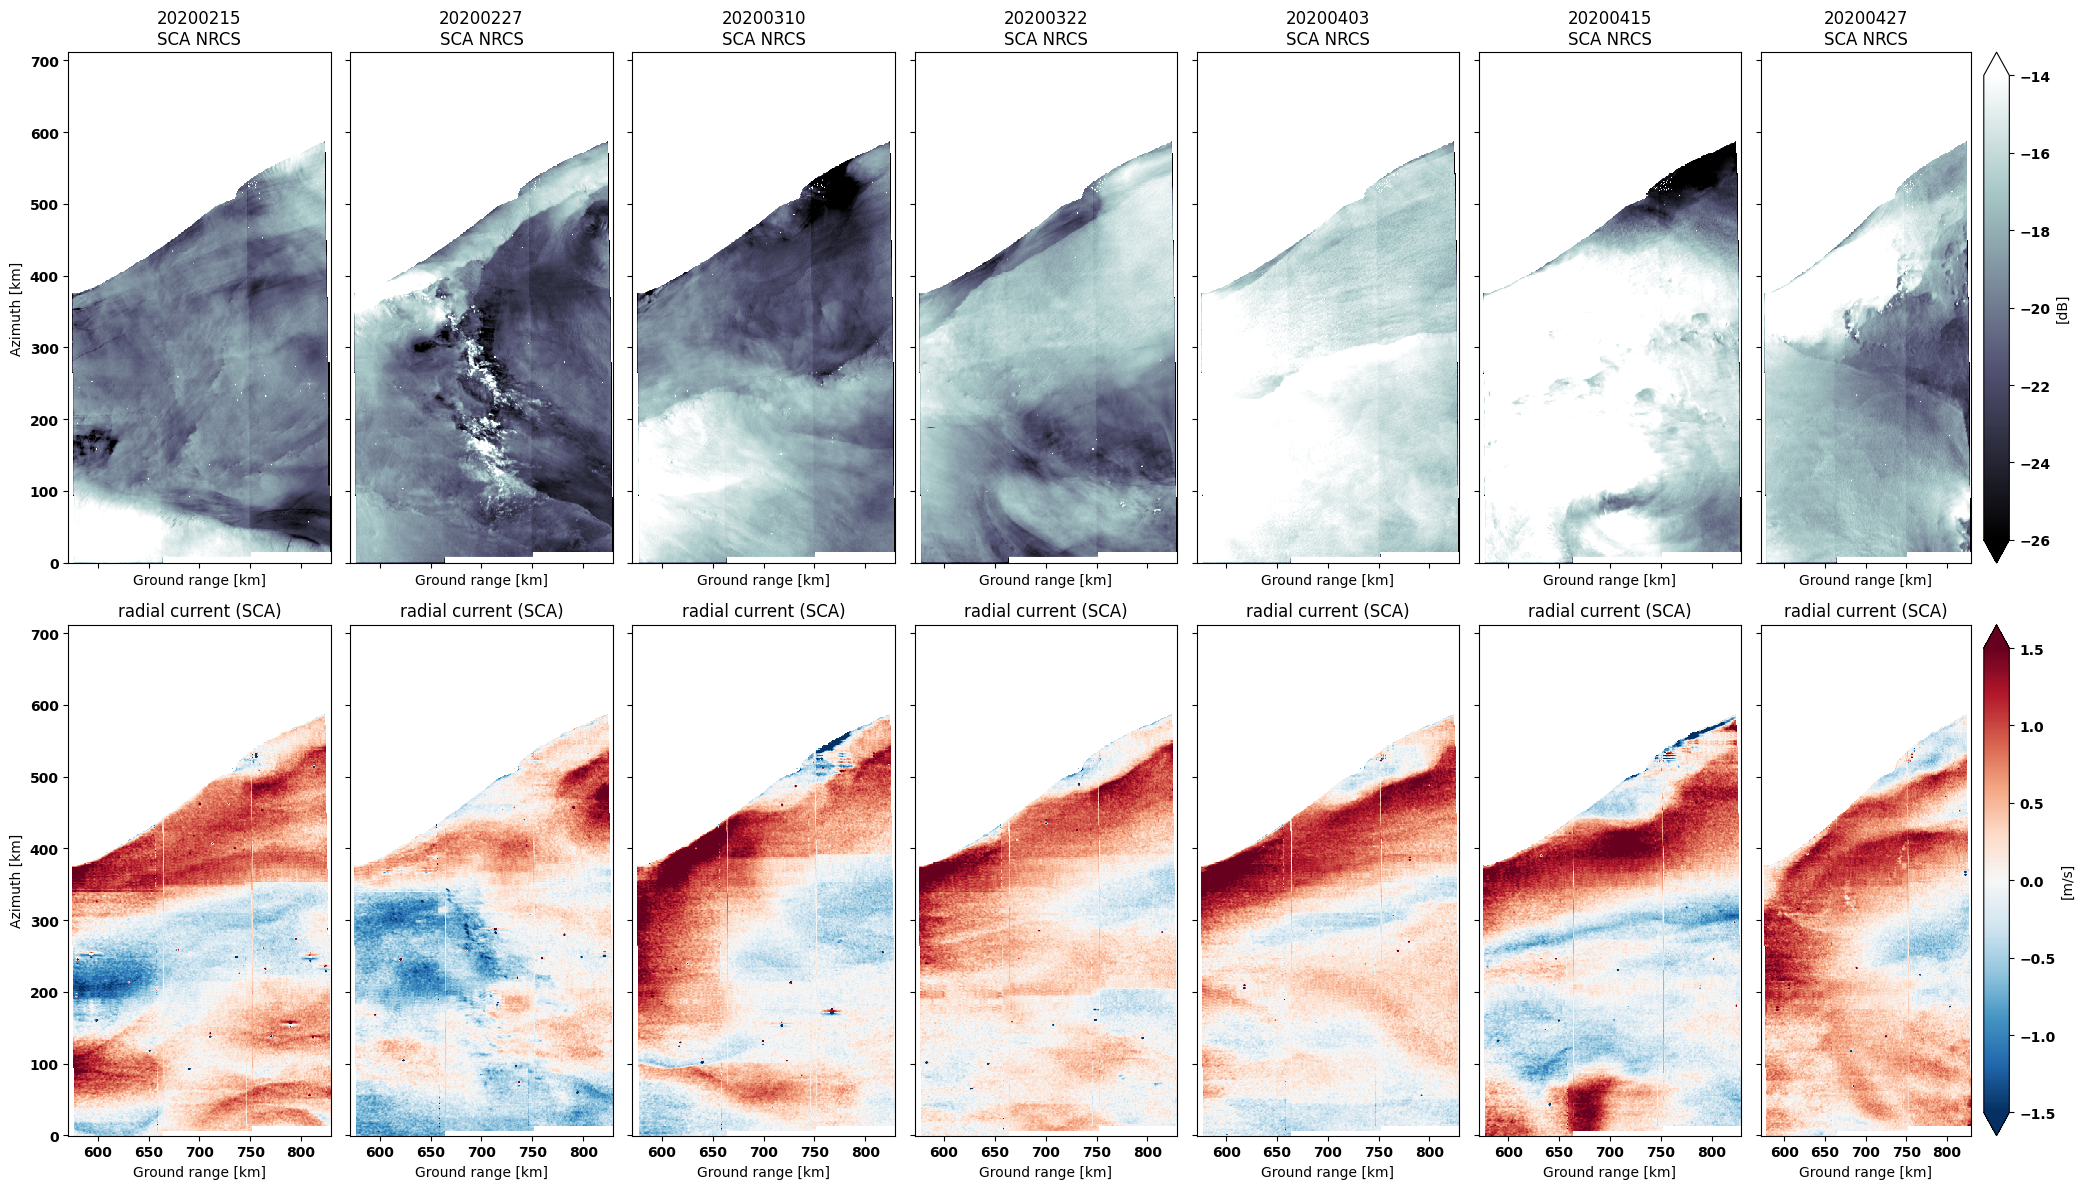

In [6]:
scenes = {date: xr.open_dataset(dir_out + f'DATA-2_Agulhas_{date}_SCA.nc') for date in dates}

fig, axes = plt.subplots(ncols=len(dates), nrows=2, sharex=True, sharey=True, figsize = (3 * len(dates), 12))
for i, date in enumerate(dates):
    scene = scenes[date].assign_coords(az = scenes[date].az / 1e3, grg = scenes[date].grg / 1e3)
    velocity = dop2vel(Doppler=scene['dop'], Lambda=sca.Lambda, angle_incidence=scene['inc'], angle_azimuth=90, degrees=True)
    last = i == len(dates) - 1
    (10 * np.log10(scene['nrcs'])).plot(ax = axes[0, i], x = 'grg', cmap = 'bone', vmin = -26, vmax = -14, add_colorbar = last, cbar_kwargs={"label": "[dB]"} if last else None)
    velocity.plot(ax = axes[1, i], x = 'grg', cmap = 'RdBu_r', vmin = -1.5, vmax = 1.5, add_colorbar = last, cbar_kwargs={"label": "[m/s]"} if last else None)
    axes[0, i].set_title(f"{date}\nSCA NRCS")
    axes[1, i].set_title("radial current (SCA)")
    for ax in axes[:, i]:
        ax.set_xlabel("Ground range [km]")
        ax.set_ylabel("Azimuth [km]" if i == 0 else "")
plt.tight_layout()